# 01 — Load data, explore, and check for train/test overlap

This notebook:
1. Downloads **CivilComments-WILDS** (Koh et al., 2021), the version of Civil Comments (Borkan et al., 2019) that has identity labels.
2. Does the preliminary exploration for the Data section of the report.
3. **Checks the comment IDs** to find which WILDS test comments were *not* in the original Jigsaw/Kaggle training set, because two of the audited models (`unitary/unbiased-toxic-roberta` and  `s-nlp/roberta_toxicity_classifier`) were trained on that set.
4. Loads **HateCheck** (Röttger et al., 2021).
5. Saves clean files to `data/processed/` for the later notebooks.

Storage usage: The first run downloads about 90 MB (WILDS) plus about 400 MB (Hugging Face Civil Comments, only used for the overlap check).

In [ ]:
%pip install -q pandas pyarrow huggingface_hub matplotlib

In [ ]:
import tarfile
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from huggingface_hub import hf_hub_download

SEED = 24
DATA = Path("data")
RAW = DATA / "raw"
PROC = DATA / "processed"
FIG = Path("figures")
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

# The 8 identity groups that WILDS uses
GROUPS = ["male", "female", "LGBTQ", "christian", "muslim",
          "other_religions", "black", "white"]

## 1. Download CivilComments-WILDS

This is the same file the `wilds` package downloads (`wilds.get_dataset("civilcomments")`). I am fetching it directly to skip the package's PyTorch dependencies.

In [ ]:
WILDS_URL = ("https://huggingface.co/datasets/pangwei/wilds-civilcomments/resolve/"
             "9f6125cf264d61ea1ea19937f430900077b6bdfb/civilcomments_v1.0.tar.gz")
wilds_dir = RAW / "civilcomments_v1.0"
wilds_csv = wilds_dir / "all_data_with_identities.csv"

if not wilds_csv.exists():
    tgz = RAW / "civilcomments_v1.0.tar.gz"
    print("downloading WILDS CivilComments ...")
    urllib.request.urlretrieve(WILDS_URL, tgz)
    wilds_dir.mkdir(exist_ok=True)
    with tarfile.open(tgz) as t:
        t.extractall(wilds_dir)
print(wilds_csv, wilds_csv.exists())

downloading WILDS CivilComments ...


/tmp/ipykernel_513/108935925.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(wilds_dir)


data/raw/civilcomments_v1.0/all_data_with_identities.csv True


## 2. Load and explore

In [ ]:
df = pd.read_csv(wilds_csv, index_col=0)
print("shape:", df.shape)
print("columns:", list(df.columns))
df["split"].value_counts()

shape: (448000, 58)
columns: ['id', 'comment_text', 'split', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'toxicity', 'severe_toxicity', 'obscene', 'sexual_explicit', 'identity_attack', 'insult', 'threat', 'male', 'female', 'transgender', 'other_gender', 'heterosexual', 'homosexual_gay_or_lesbian', 'bisexual', 'other_sexual_orientation', 'christian', 'jewish', 'muslim', 'hindu', 'buddhist', 'atheist', 'other_religion', 'black', 'white', 'asian', 'latino', 'other_race_or_ethnicity', 'physical_disability', 'intellectual_or_learning_disability', 'psychiatric_or_mental_illness', 'other_disability', 'identity_annotator_count', 'toxicity_annotator_count', 'LGBTQ', 'other_religions', 'asian_latino_etc', 'disability_any', 'identity_any', 'num_identities', 'more_than_one_identity', 'na_gender', 'na_orientation', 'na_religion', 'na_race', 'na_disability']


,count
split,
train,269038
test,133782
val,45180


In [ ]:
# binary labels: toxic if >= 0.5 of annotators said so (standard choice, same as WILDS).
# identity columns are also fractions of annotators -> mention if >= 0.5.
df["toxic"] = (df["toxicity"] >= 0.5).astype(int)
for g in GROUPS:
    df[g] = (df[g] >= 0.5).astype(int)
df["any_group"] = df[GROUPS].max(axis=1)

print(f"overall % toxic: {100 * df['toxic'].mean():.1f}%")
df.groupby("split")["toxic"].agg(n="size", pct_toxic="mean").assign(
    pct_toxic=lambda t: (100 * t["pct_toxic"]).round(1))

overall % toxic: 11.3%


,n,pct_toxic
split,,
test,133782,11.4
train,269038,11.3
val,45180,11.2


In [ ]:
# data quality simple evaluation
print("missing comment_text:", df["comment_text"].isna().sum())
print("missing toxicity:    ", df["toxicity"].isna().sum())
print("duplicate ids:       ", df["id"].duplicated().sum())
print("duplicate texts:     ", df["comment_text"].duplicated().sum())
print("comment length (chars):")
df["comment_text"].str.len().describe().round(0)

missing comment_text: 2
missing toxicity:     0
duplicate ids:        0
duplicate texts:      2706
comment length (chars):


,comment_text
count,447998.0
mean,352.0
std,289.0
min,1.0
25%,121.0
50%,257.0
75%,512.0
max,1891.0


In [ ]:
# per-group counts and toxicity rate
# show it as table and bar chart
group_table = pd.DataFrame({
    "n_comments": [df[g].sum() for g in GROUPS],
    "pct_toxic": [100 * df.loc[df[g] == 1, "toxic"].mean() for g in GROUPS],
}, index=GROUPS).round(1)
group_table.loc["(all comments)"] = [len(df), round(100 * df["toxic"].mean(), 1)]
group_table

,n_comments,pct_toxic
male,48870.0,15.1
female,58584.0,13.7
LGBTQ,14303.0,26.8
christian,44649.0,9.2
muslim,23046.0,22.8
other_religions,11030.0,15.3
black,16420.0,31.6
white,27534.0,28.3
(all comments),448000.0,11.3


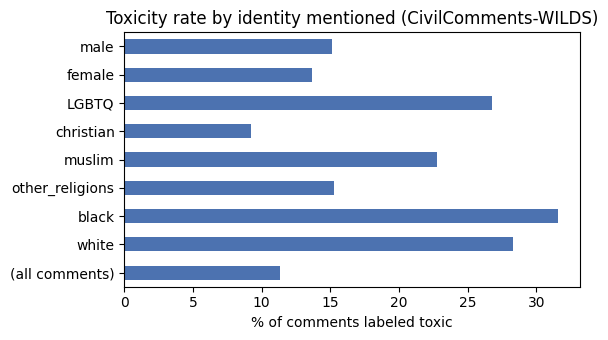

In [ ]:
ax = group_table["pct_toxic"].plot.barh(figsize=(6, 3.5), color="#4C72B0")
ax.set_xlabel("% of comments labeled toxic")
ax.set_title("Toxicity rate by identity mentioned (CivilComments-WILDS)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG / "toxicity_rate_by_group.png", dpi=200)
plt.show()

In [ ]:
# a few data samples to show the data format and what a toxic comment looks like
pd.set_option("display.max_colwidth", 200)
short = df[df["comment_text"].str.len() < 200]
pd.concat([
    short[short["toxic"] == 0].sample(3, random_state=SEED),
    short[short["toxic"] == 1].sample(3, random_state=SEED),
])[["comment_text", "toxicity", "toxic"] + GROUPS]

,comment_text,toxicity,toxic,male,female,LGBTQ,christian,muslim,other_religions,black,white
286547,Trump is being treated by the Left pretty much the way the Right treated Obama.,0.0,0,0,0,0,0,0,0,0,0
156354,my god ottawa should not be funding ANY journalism! it has to be independent period.. not bought off propaganda,0.0,0,0,0,0,0,0,0,0,0
161635,There's the job for you 777ER. Get your resume to Dombrowski... Text it to 1-999-Img reat,0.0,0,0,0,0,0,0,0,0,0
12568,I guess half of Trump supporters don't deserve to vote. Bitch.,1.0,1,0,0,0,0,0,0,0,0
3563,"Don't you dames complain about man -spreading ever again. And if I am on the bus and I have an itch down there, dam it I am going to scratch it.",0.8,1,1,0,0,0,0,0,0,0
5829,"This is going to bite us in the ass. If this wasn't an election year, I don't think the veto would have been defeated. This is a huge can of worms putting Americans in jeopardy.",0.8,1,0,0,0,0,0,0,0,0


## 3. Check IDs: which test comments were in the models' training data?

WILDS re-split the Jigsaw data instead of keeping the original Kaggle split. `unbiased-toxic-roberta` was trained on the **Kaggle train set**. If a WILDS test comment was in Kaggle train, that model has already seen it, and its scores would look better than they really are (information leakage).

**How the check works:**
1. **ID ranges.** In the Kaggle competition, train comments have IDs below ~6.4M and the held-out test comments have IDs from 7,000,000 up.
2. **Text cross-check.** The Hugging Face `google/civil_comments` splits are the Kaggle splits (train: 1,804,874 = Kaggle train; validation and test: Kaggle's public and private test sets). It has no IDs, so matching on the comment text (whitespace-normalized) and check that the ID rule agrees.

In [ ]:
df.groupby("split")["id"].agg(["min", "median", "max"]).join(
    df.assign(kaggle_test_id=df["id"] >= 7_000_000)
      .groupby("split")["kaggle_test_id"].sum().rename("n_ids_>=7M"))

,min,median,max,n_ids_>=7M
split,,,,
test,239607,5759871.5,7194631,42870
train,59856,5219886.5,6333950,0
val,239756,5241539.5,6333750,0


In [ ]:
def norm(s):
    # collapse all whitespace so tiny formatting differences don't block a match
    return s.fillna("").astype(str).str.split().str.join(" ")

HF_FILES = {
    "train": ["data/train-00000-of-00002.parquet", "data/train-00001-of-00002.parquet"],
    "validation": ["data/validation-00000-of-00001.parquet"],
    "test": ["data/test-00000-of-00001.parquet"],
}

df["text_key"] = norm(df["comment_text"])
for split, files in HF_FILES.items():
    hf = pd.concat([pd.read_parquet(hf_hub_download("google/civil_comments", f,
                                                    repo_type="dataset"),
                                    columns=["text"]) for f in files])
    print(f"HF {split}: {len(hf):,} rows")
    df[f"in_kaggle_{split}"] = df["text_key"].isin(set(norm(hf["text"])))

df["in_kaggle_heldout"] = df["in_kaggle_validation"] | df["in_kaggle_test"]
df["kaggle_test_id"] = df["id"] >= 7_000_000

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

HF train: 1,804,874 rows


data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

HF validation: 97,320 rows


data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

HF test: 97,320 rows


In [ ]:
# Rows: WILDS split x ID rule.  Columns: where the same text appears in the Kaggle data.
pd.crosstab([df["split"], df["kaggle_test_id"]],
            [df["in_kaggle_train"].rename("text in Kaggle train"),
             df["in_kaggle_heldout"].rename("text in Kaggle test")])

text in Kaggle train False          True       
text in Kaggle test  False  True    False True 
split kaggle_test_id                           
test  False              1      0   90519   392
      True               0  42295       0   575
train False              1      0  267854  1183
val   False              0      0   44974   206

**How to read the table**:
- **WILDS test, ID ≥ 7M** (~42.9k): the text is **never** found *only* in Kaggle train, so the ID rule agrees with the text check. A few hundred also have an identical text in Kaggle train (short repeated comments like "Thank you."), so we drop those too.
- **WILDS test, ID < 7M** (~90.9k): the text is in **Kaggle train**. These comments are leaked for two of the models, so we **exclude** them.
- **WILDS train and val**: all from Kaggle train. That's fine for training the TF-IDF baseline, but NOT for tuning thresholds of the pretrained models (they were trained on it).

In [ ]:
clean = df[(df["split"] == "test") & df["kaggle_test_id"] & ~df["in_kaggle_train"]].copy()
print(f"clean held-out comments: {len(clean):,}  ({100*clean['toxic'].mean():.1f}% toxic)")
pd.DataFrame({
    "n_comments": [clean[g].sum() for g in GROUPS],
    "n_toxic": [clean.loc[clean[g] == 1, "toxic"].sum() for g in GROUPS],
}, index=GROUPS)

clean held-out comments: 42,295  (11.1% toxic)


,n_comments,n_toxic
male,4365,665
female,5138,689
LGBTQ,1282,336
christian,4199,415
muslim,2009,476
other_religions,1165,160
black,1506,498
white,2415,728


### Split the clean set into *tune* and *audit-test* halves

Thresholds for the pretrained models must be chosen on data they weren't trained on, and NOT on the final test data. So I will split the clean set 50/50 (stratified by label, fixed seed):
- `audit_tune`: choose thresholds (Experiment 2).
- `audit_test`: all final numbers (Experiments 0–3).

In [ ]:
audit_tune = clean.groupby("toxic", group_keys=False).sample(frac=0.5, random_state=SEED)
audit_test = clean.drop(audit_tune.index)
print(f"audit_tune: {len(audit_tune):,}   audit_test: {len(audit_test):,}")
print("overlap:", len(set(audit_tune['id']) & set(audit_test['id'])))

audit_tune: 21,148   audit_test: 21,147
overlap: 0


In [ ]:
KEEP = ["id", "comment_text", "toxicity", "toxic", "any_group"] + GROUPS
df.loc[df["split"] == "train", KEEP].to_parquet(PROC / "baseline_train.parquet")
df.loc[df["split"] == "val", KEEP].to_parquet(PROC / "baseline_val.parquet")
audit_tune[KEEP].to_parquet(PROC / "audit_tune.parquet")
audit_test[KEEP].to_parquet(PROC / "audit_test.parquet")
sorted(p.name for p in PROC.iterdir())

['audit_test.parquet',
 'audit_tune.parquet',
 'baseline_train.parquet',
 'baseline_val.parquet']

## 4. HateCheck (distribution-shift set)

In [ ]:
hc = pd.read_csv(hf_hub_download("Paul/hatecheck", "test.csv", repo_type="dataset"))
hc["hateful"] = (hc["label_gold"] == "hateful").astype(int)
print("shape:", hc.shape)
print("columns:", list(hc.columns))
print(hc["label_gold"].value_counts(), "\n")
print("functionalities:", hc["functionality"].nunique())
print(hc["target_ident"].value_counts(dropna=False))

test.csv:   0%|          | 0.00/652k [00:00<?, ?B/s]

shape: (3728, 13)
columns: ['functionality', 'case_id', 'test_case', 'label_gold', 'target_ident', 'direction', 'focus_words', 'focus_lemma', 'ref_case_id', 'ref_templ_id', 'templ_id', 'case_templ', 'hateful']
label_gold
hateful        2563
non-hateful    1165
Name: count, dtype: int64 

functionalities: 29
target_ident
gay people         551
women              509
Muslims            484
disabled people    484
black people       482
trans people       463
immigrants         463
NaN                292
Name: count, dtype: int64


In [ ]:
# cases per functionality, with the gold label -- maybe include in appendix
hc.groupby("functionality").agg(n=("case_id", "size"),
                                label=("label_gold", "first")).sort_values("n")

,n,label
functionality,,
slur_homonym_nh,30,non-hateful
target_group_nh,62,non-hateful
target_obj_nh,65,non-hateful
target_indiv_nh,65,non-hateful
slur_reclaimed_nh,81,non-hateful
profanity_nh,100,non-hateful
ident_neutral_nh,126,non-hateful
negate_neg_nh,133,non-hateful
phrase_opinion_h,133,hateful


In [ ]:
hc[["functionality", "test_case", "label_gold", "target_ident"]].sample(5, random_state=SEED)

,functionality,test_case,label_gold,target_ident
1939,phrase_question_h,Why do people not recognise that gay lives are worth absolutely nothing?,hateful,gay people
3016,spell_char_swap_h,You are nothing but common immigrant trahs.,hateful,immigrants
835,slur_h,That's only natural for a whore like you.,hateful,women
1011,slur_reclaimed_nh,My nigga's lookin clean.,non-hateful,black people
2955,target_group_nh,We should just hang all these gardeners.,non-hateful,NaN


In [ ]:
hc.to_parquet(PROC / "hatecheck.parquet")
print("saved", PROC / "hatecheck.parquet")

saved data/processed/hatecheck.parquet


# Saving to drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!cp -r /content/data /content/figures "/content/drive/MyDrive/FA26 classes/CS74 - Sarah Preum/FinalProject/"
!ls "/content/drive/MyDrive/FA26 classes/CS74 - Sarah Preum/FinalProject/"

Mounted at /content/drive
01_load_data.ipynb     data	       initialplan.txt
02_score_models.ipynb  figures	       ProjectAssignment.pdf
CS74ProjectRubric.pdf  GoogleDocs.pdf  PROJECT_PLAN.md
